# 13-AI指令到机器人肌肉运动


## 1. 本课目标：把 Action 变成目标关节角

本篇对应《具身智能机器人实战》第 13 节《AI 指令到机器人肌肉运动》，副标题为“打通任督二脉 action_scale default_Q”。上一节解释策略接收的观测，本节继续看策略输出：神经网络给出的动作数值，怎样转换成机器人关节应该到达的角度？

**资料依据：**[课程百度网盘资料](https://pan.baidu.com/s/1TI1Opoqy_jjmWCzhUOwliw?pwd=1234)，提取码 `1234`。已逐页核对 `ppt/13_AI指令到肌肉运动.pptx` 全部 5 页：第 2 页介绍动作缩放，第 3 页根据角度范围推导缩放量，第 4 页加入默认姿态，第 5 页为品牌结束页。

本节的核心是两个量：`ACTION_SCALE` 决定相对调整的幅度，`DEFAULT_Q` 决定调整所依据的基准姿态。课件没有提供实际配置数组或控制代码；下面按课件顺序整理公式和示例，必要的条件说明标为“工程补充”。未转录配套视频 `13_ai指令到机器人肌肉运动.mp4`，也未读取网盘中的 `code.zip`。


## 2. ACTION_SCALE：给网络动作一个角度尺度

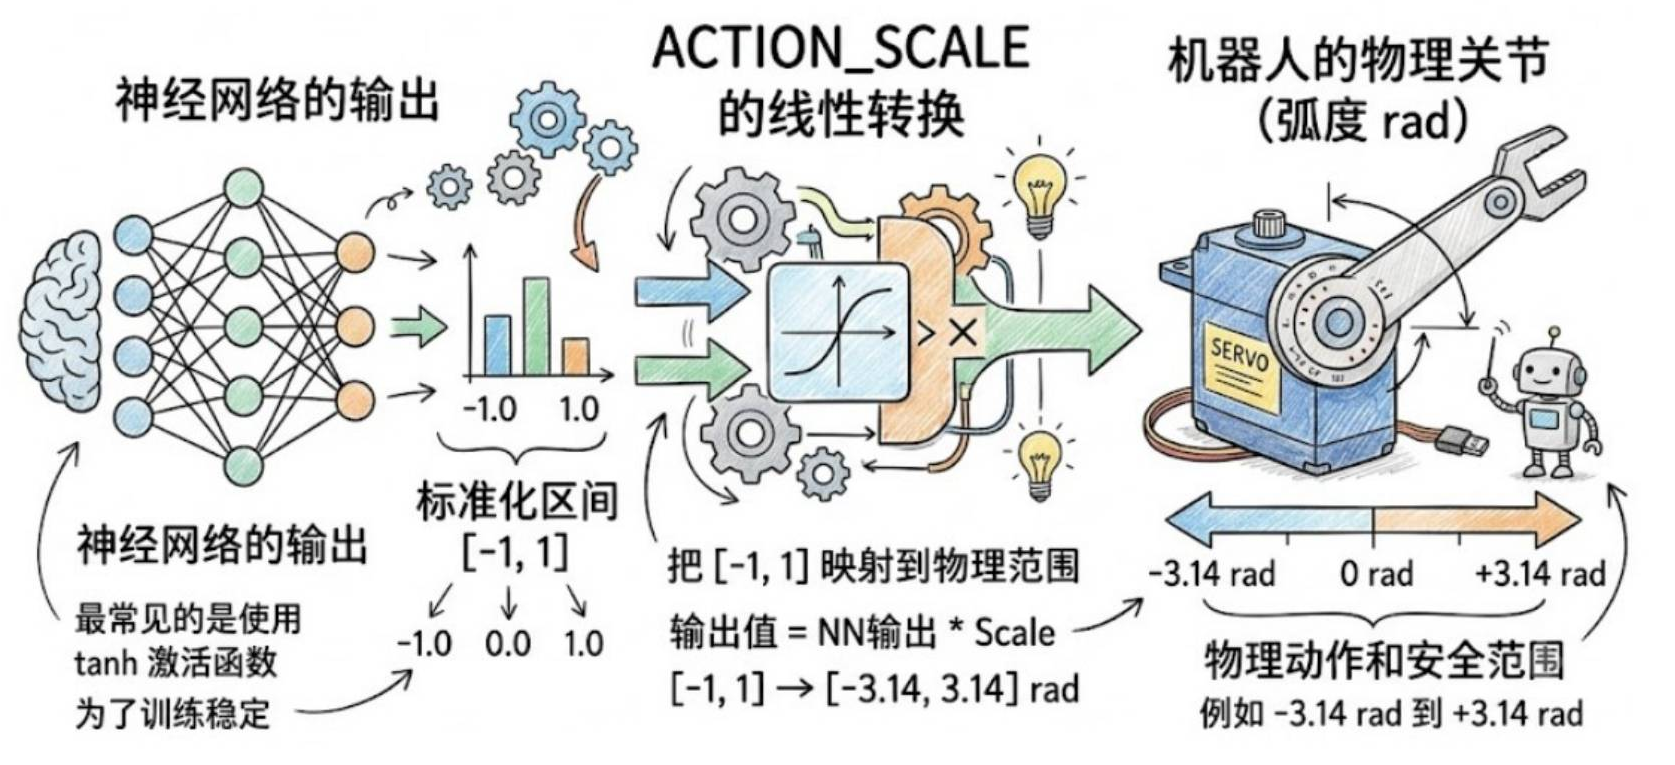

*原课件第 2 页：网络输出以 `[-1, 1]` 为例，乘以 Scale 后映射到以弧度表示的角度范围。*

神经网络的输出首先是数值。课件用归一化动作 `action ∈ [-1, 1]` 说明转换过程，并以 `tanh` 激活函数为例，解释把输出限制在统一范围有助于训练稳定。

这些数值不能直接当作所有关节通用的角度。比如同样输出 `0.5`，实际希望关节偏转多少，需要用缩放系数说明：

$$
\Delta q=action\times ACTION\_SCALE
$$

这里 `action` 是无量纲的动作分量，`ACTION_SCALE` 给它角度尺度，得到的 `Δq` 用弧度（rad）表示。按图中的示例，取 `ACTION_SCALE = 3.14 rad`：

$$
[-1,\,0,\,1]\times3.14
=[-3.14,\,0,\,3.14]\ \mathrm{rad}
$$

动作的绝对值越大，相对调整幅度越大；动作的正负号决定相对基准往哪个角度方向调整。

**工程补充：**这一页先演示以零为中心的缩放，后面还要加入 `DEFAULT_Q` 才得到完整目标角。图中的 `±3.14 rad` 是示意范围，不是 T800 全部关节的实际限位；`tanh` 也是课件的说明例子，不能据此断定实际策略一定使用该激活函数，或未经核对就假设其输出始终在 `[-1, 1]`。


## 3. 缩放量从哪里来：关节范围与肘关节示例

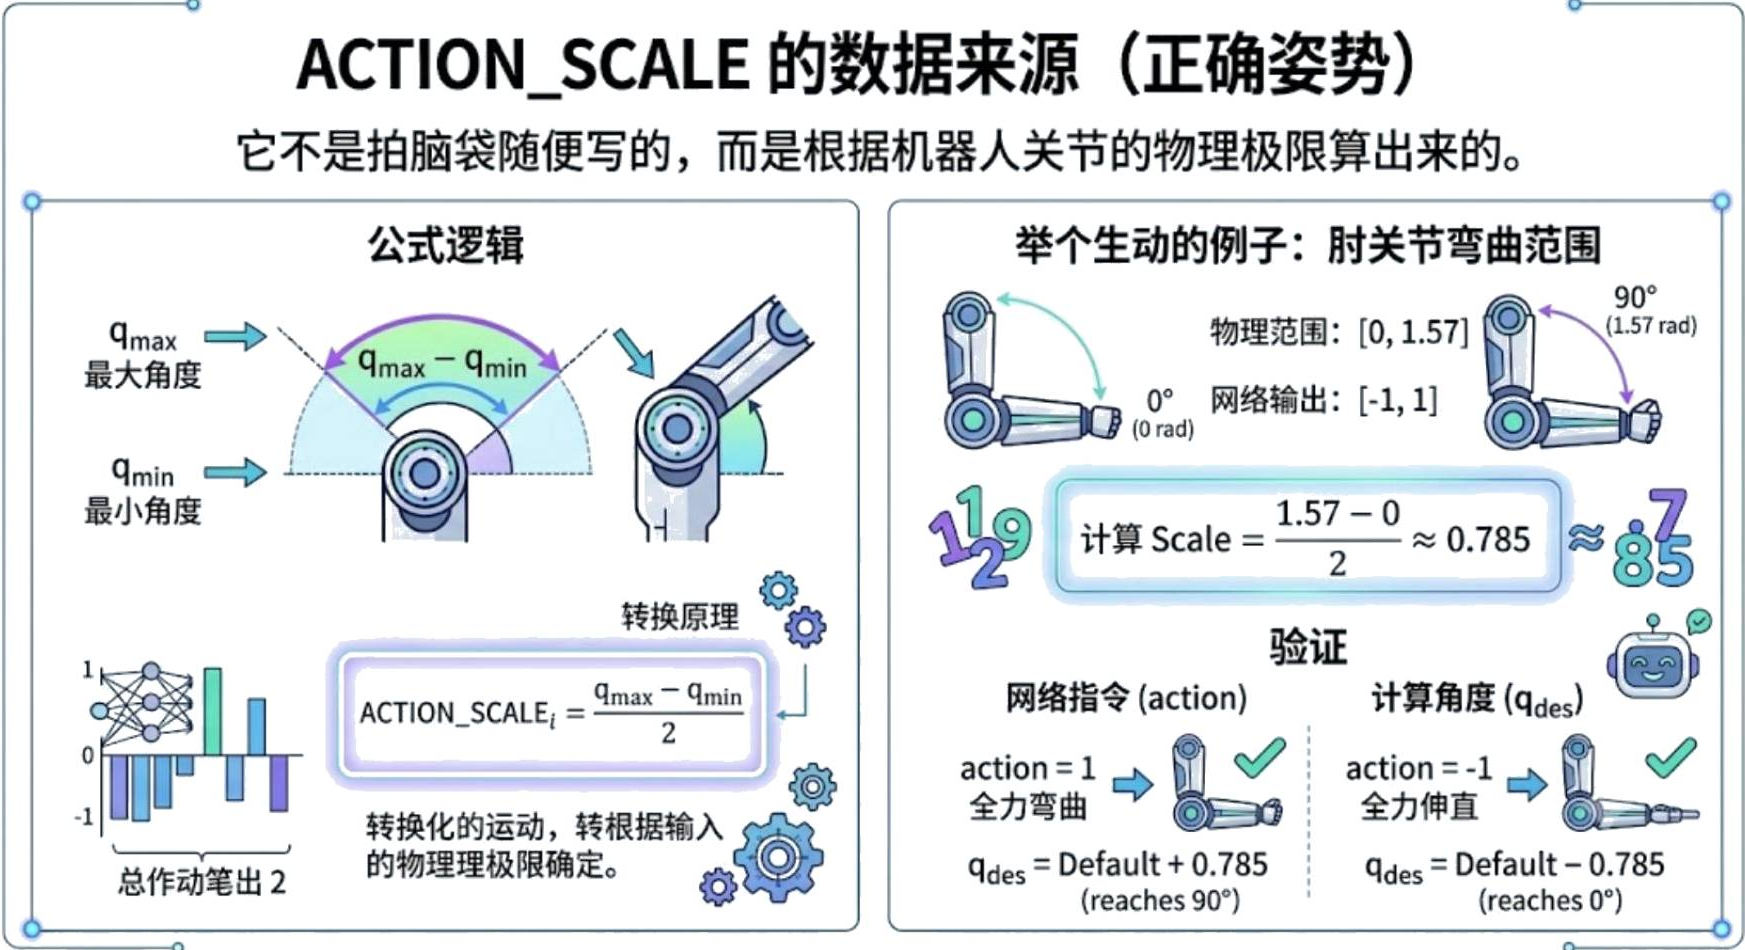

*原课件第 3 页：用角度范围的一半作为 Scale，并用 `0～1.57 rad` 的肘关节解释两个动作端点。*

课件强调，`ACTION_SCALE` 需要结合关节的物理范围确定。设第 `i` 个关节的最小、最大角度分别为 `q_min,i` 和 `q_max,i`。归一化区间 `[-1, 1]` 的总宽度为 2，要对应整个角度区间，缩放量就是角度跨度的一半：

$$
ACTION\_SCALE_i=\frac{q_{\max,i}-q_{\min,i}}{2}
$$

课件给出一个肘关节例子：伸直为 `0 rad`，弯曲到约 90° 为 `1.57 rad`。于是：

$$
ACTION\_SCALE=\frac{1.57-0}{2}=0.785\ \mathrm{rad}
$$

图中把 `action = 1` 描述为“全力弯曲”，对应 `q_des = Default + 0.785`；把 `action = -1` 描述为“全力伸直”，对应 `q_des = Default - 0.785`。

**工程补充：这两个端点还要求 Default 位于范围中点。**本例应取：

$$
Default=\frac{q_{\max}+q_{\min}}{2}
=\frac{1.57+0}{2}=0.785\ \mathrm{rad}
$$

把这个基准角代入后，课件中的两端才成立：

| 网络动作 | 目标角计算 | 本例中的目标姿态 |
|---:|---|---|
| `-1` | `0.785 - 0.785 = 0 rad` | 伸直，约 0° |
| `0` | `0.785 + 0 = 0.785 rad` | 中间位置，约 45° |
| `1` | `0.785 + 0.785 = 1.57 rad` | 弯曲，约 90° |

因此，将 `[-1, 1]` 完整对应到 `[q_min, q_max]` 的公式是：

$$
q_{\mathrm{des}}=
\frac{q_{\max}+q_{\min}}{2}
+action\times\frac{q_{\max}-q_{\min}}{2}
$$

如果实际准备姿态不在中点，就不能仅凭“半个角度跨度”保证目标不越界。例如仍取 Scale 为 `0.785 rad`，但 Default 改成 `0.2 rad`，则 `action = -1` 得到 `-0.585 rad`，已低于本例下限。实际接入策略时，应核对训练与部署共同使用的默认姿态、缩放量及动作限幅，不能把这一推导直接当作实际配置覆盖进去。

图中的“全力”表示动作取到了归一化端点，并不表示施加最大电机力矩。正动作对应弯曲也是本例的角度约定，其他关节的正方向需结合关节轴定义。


## 4. DEFAULT_Q：在准备姿态上学习“动多少”

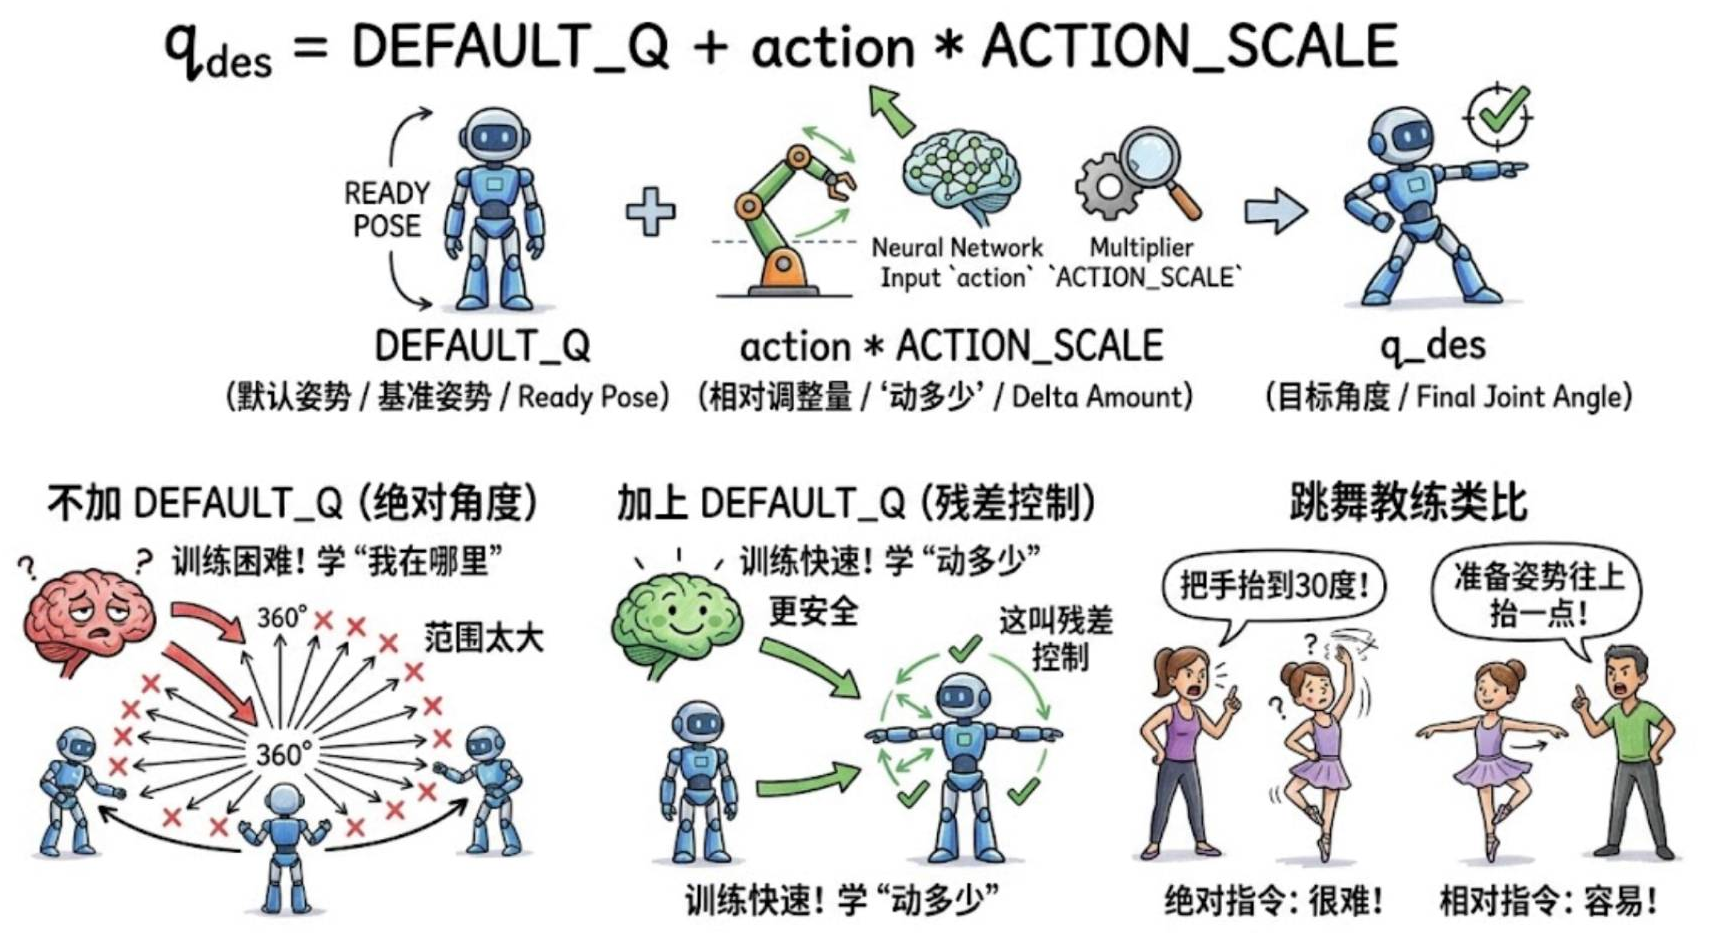

*原课件第 4 页：默认姿态 + 相对调整量 = 目标角度；用跳舞教练的指令解释绝对角度与相对调整的区别。*

加入默认姿态后，得到本课的完整公式：

$$
q_{\mathrm{des},i}=DEFAULT\_Q_i
+action_i\times ACTION\_SCALE_i
$$

| 量 | 含义 | 在转换中的作用 |
|---|---|---|
| `DEFAULT_Q` | 默认姿态、基准姿态，也称 Ready Pose | 提供每个关节的参考角 |
| `action × ACTION_SCALE` | 相对调整量，即“动多少” | 决定相对基准偏转多少 |
| `q_des` | 目标关节角 | 交给后续关节控制环节跟踪 |

课件把不加 `DEFAULT_Q` 的方式称为输出绝对角度：网络需要在较大角度范围内学习合适的姿态。加入默认姿态后，网络围绕已有的准备姿态学习调整量，这里称为**残差控制**。

跳舞教练的类比是：直接说“把手抬到 30 度”，学习者需要理解这个绝对位置；说“准备姿势往上抬一点”，则先有共同的准备姿态，再学习调整多少。`DEFAULT_Q` 就相当于共同的准备姿态，缩放后的 Action 相当于“往上抬一点”。

课件据此强调，围绕合理姿态学习调整量，有利于减轻学习负担、加快训练，并把动作安排在较合适的范围内。

**工程补充：**这里的相对调整以 `DEFAULT_Q` 为基准，不是每一步都加到当前实测角度上。`action = 0` 时目标就是默认角；`action = 1` 时目标是默认角加 Scale。只要默认角、Scale 与动作不变，连续给出同一个动作得到的目标也不变，不会逐帧累加。

`q_des` 是期望到达的角度，不是关节已经到达的实测角度。沿用前几篇介绍的力矩控制链路，目标角还需经过 PD 计算、力矩限幅与执行器作用，仿真推进后才会改变实际状态。角度缩放不能代替力矩限幅。

图中的“360°”用于说明搜索范围较大的情形，不能当作所有关节的真实活动范围；“训练快速、更安全”是采用参考姿态的动机，效果仍取决于基准、幅度和控制参数是否合适。对本课程的策略，还需让 Action、`DEFAULT_Q`、`ACTION_SCALE` 与选定关节一一对应，沿用同一顺序；上一节的 22 个关节相关分量并不能直接套到全部 25 个 motor 上。


## 5. 本课检查

本节按“先缩放、再加基准”的思路，把网络动作转换为目标关节角：

$$
\underbrace{q_{\mathrm{des}}}_{\text{目标角}}
=\underbrace{DEFAULT\_Q}_{\text{基准角}}
+\underbrace{action\times ACTION\_SCALE}_{\text{相对调整量}}
$$

完成本节，应能解释 Scale 为什么有角度单位，算出肘关节示例的 `0.785 rad`，说明端点映射依赖哪个默认角，并分清目标角、实测角和电机力矩。

本篇已核对全部课件页面并校验示例运算。课件未展示实际策略的默认姿态数组、缩放配置和关节映射，本篇没有推定这些数值，也没有执行策略推理或验证机器人运动。
